In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [22]:
# DATA PREPROCESSING
# Dataset: Heart.csv
# Apply data preprocessing and exploratory data analysis on Heart.csv. Evaluate the dataset using summary statistics, and plot one
# visualization.

df=pd.read_csv("heart.csv")
print(df.head(5))

   Unnamed: 0  Age  Sex     ChestPain  RestBP  Chol  Fbs  RestECG  MaxHR  \
0           1   63    1       typical     145   233    1        2    150   
1           2   67    1  asymptomatic     160   286    0        2    108   
2           3   67    1  asymptomatic     120   229    0        2    129   
3           4   37    1    nonanginal     130   250    0        0    187   
4           5   41    0    nontypical     130   204    0        2    172   

   ExAng  Oldpeak  Slope   Ca        Thal  AHD  
0      0      2.3      3  0.0       fixed   No  
1      1      1.5      2  3.0      normal  Yes  
2      1      2.6      2  2.0  reversable  Yes  
3      0      3.5      3  0.0      normal   No  
4      0      1.4      1  0.0      normal   No  


In [23]:
# remove unused columns
df=df.drop('Unnamed: 0',axis=1)
print(df.head(5))

   Age  Sex     ChestPain  RestBP  Chol  Fbs  RestECG  MaxHR  ExAng  Oldpeak  \
0   63    1       typical     145   233    1        2    150      0      2.3   
1   67    1  asymptomatic     160   286    0        2    108      1      1.5   
2   67    1  asymptomatic     120   229    0        2    129      1      2.6   
3   37    1    nonanginal     130   250    0        0    187      0      3.5   
4   41    0    nontypical     130   204    0        2    172      0      1.4   

   Slope   Ca        Thal  AHD  
0      3  0.0       fixed   No  
1      2  3.0      normal  Yes  
2      2  2.0  reversable  Yes  
3      3  0.0      normal   No  
4      1  0.0      normal   No  


In [24]:
df.describe()

,Age,Sex,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000
mean,54.438944,0.679868,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241
std,9.038662,0.467299,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438
min,29.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000
25%,48.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000
50%,56.000000,1.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000
75%,61.000000,1.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000
max,77.000000,1.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Age        303 non-null    int64  
 1   Sex        303 non-null    int64  
 2   ChestPain  303 non-null    object 
 3   RestBP     303 non-null    int64  
 4   Chol       303 non-null    int64  
 5   Fbs        303 non-null    int64  
 6   RestECG    303 non-null    int64  
 7   MaxHR      303 non-null    int64  
 8   ExAng      303 non-null    int64  
 9   Oldpeak    303 non-null    float64
 10  Slope      303 non-null    int64  
 11  Ca         299 non-null    float64
 12  Thal       301 non-null    object 
 13  AHD        303 non-null    object 
dtypes: float64(2), int64(9), object(3)
memory usage: 33.3+ KB


In [26]:
df.isnull().sum()

Age          0
Sex          0
ChestPain    0
RestBP       0
Chol         0
Fbs          0
RestECG      0
MaxHR        0
ExAng        0
Oldpeak      0
Slope        0
Ca           4
Thal         2
AHD          0
dtype: int64

In [27]:
# remove columns that do not have target
df=df.dropna(subset=['AHD'])
print(df.head(5))

   Age  Sex     ChestPain  RestBP  Chol  Fbs  RestECG  MaxHR  ExAng  Oldpeak  \
0   63    1       typical     145   233    1        2    150      0      2.3   
1   67    1  asymptomatic     160   286    0        2    108      1      1.5   
2   67    1  asymptomatic     120   229    0        2    129      1      2.6   
3   37    1    nonanginal     130   250    0        0    187      0      3.5   
4   41    0    nontypical     130   204    0        2    172      0      1.4   

   Slope   Ca        Thal  AHD  
0      3  0.0       fixed   No  
1      2  3.0      normal  Yes  
2      2  2.0  reversable  Yes  
3      3  0.0      normal   No  
4      1  0.0      normal   No  


In [28]:
df.dtypes

Age            int64
Sex            int64
ChestPain     object
RestBP         int64
Chol           int64
Fbs            int64
RestECG        int64
MaxHR          int64
ExAng          int64
Oldpeak      float64
Slope          int64
Ca           float64
Thal          object
AHD           object
dtype: object

In [29]:
from sklearn.preprocessing import LabelEncoder
col=['ChestPain','Thal','AHD']

label=LabelEncoder()
df['ChestPain']=label.fit_transform(df['ChestPain'])
df['Thal']=label.fit_transform(df['Thal'])
df['AHD']=label.fit_transform(df['AHD'])

print(df.head(5))

   Age  Sex  ChestPain  RestBP  Chol  Fbs  RestECG  MaxHR  ExAng  Oldpeak  \
0   63    1          3     145   233    1        2    150      0      2.3   
1   67    1          0     160   286    0        2    108      1      1.5   
2   67    1          0     120   229    0        2    129      1      2.6   
3   37    1          1     130   250    0        0    187      0      3.5   
4   41    0          2     130   204    0        2    172      0      1.4   

   Slope   Ca  Thal  AHD  
0      3  0.0     0    0  
1      2  3.0     1    1  
2      2  2.0     2    1  
3      3  0.0     1    0  
4      1  0.0     1    0  


In [33]:
df.duplicated().sum()
print(df.dtypes)

Age            int64
Sex            int64
ChestPain      int64
RestBP         int64
Chol           int64
Fbs            int64
RestECG        int64
MaxHR          int64
ExAng          int64
Oldpeak      float64
Slope          int64
Ca           float64
Thal           int64
AHD            int64
dtype: object


In [34]:
# handle missing value

for col in df.columns:
    if df[col].dtypes=='object':
        df[col]=df[col].fillna(df[col].mode().iloc[0])
    else:
        df[col]=df[col].fillna(df[col].mean())

print(df.head(5))
print(df.dtypes)

   Age  Sex  ChestPain  RestBP  Chol  Fbs  RestECG  MaxHR  ExAng  Oldpeak  \
0   63    1          3     145   233    1        2    150      0      2.3   
1   67    1          0     160   286    0        2    108      1      1.5   
2   67    1          0     120   229    0        2    129      1      2.6   
3   37    1          1     130   250    0        0    187      0      3.5   
4   41    0          2     130   204    0        2    172      0      1.4   

   Slope   Ca  Thal  AHD  
0      3  0.0     0    0  
1      2  3.0     1    1  
2      2  2.0     2    1  
3      3  0.0     1    0  
4      1  0.0     1    0  
Age            int64
Sex            int64
ChestPain      int64
RestBP         int64
Chol           int64
Fbs            int64
RestECG        int64
MaxHR          int64
ExAng          int64
Oldpeak      float64
Slope          int64
Ca           float64
Thal           int64
AHD            int64
dtype: object


In [35]:
x=df.drop('AHD',axis=1)
y=df['AHD']

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.25,random_state=42,stratify=y)

print(len(x_train))
print(len(x_test))
print(len(y_train))
print(len(y_test))


227
76
227
76


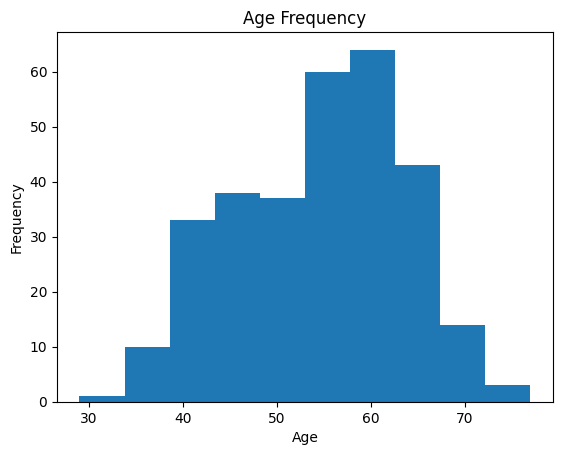

In [37]:
# visualisation
plt.hist(df['Age'],bins=10,label="Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Age Frequency")
plt.show()

In [40]:
from matplotlib import pyplot
print(dir(pyplot))

['AbstractContextManager', 'Annotation', 'Arrow', 'Artist', 'AutoLocator', 'AxLine', 'Axes', 'BackendFilter', 'Button', 'Circle', 'Colorizer', 'ColorizingArtist', 'Colormap', 'Enum', 'ExitStack', 'Figure', 'FigureBase', 'FigureCanvasBase', 'FigureManagerBase', 'FixedFormatter', 'FixedLocator', 'FormatStrFormatter', 'Formatter', 'FuncFormatter', 'GridSpec', 'IndexLocator', 'Line2D', 'LinearLocator', 'Locator', 'LogFormatter', 'LogFormatterExponent', 'LogFormatterMathtext', 'LogLocator', 'MaxNLocator', 'MouseButton', 'MultipleLocator', 'Normalize', 'NullFormatter', 'NullLocator', 'PolarAxes', 'Polygon', 'Rectangle', 'ScalarFormatter', 'Slider', 'Subplot', 'SubplotSpec', 'TYPE_CHECKING', 'Text', 'TickHelper', 'Widget', '_ColorizerInterface', '_NO_PYPLOT_NOTE', '_REPL_DISPLAYHOOK', '_ReplDisplayHook', '__annotations__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', '_add_pyplot_note', '_api', '_auto_draw_if_interactive', '_backend

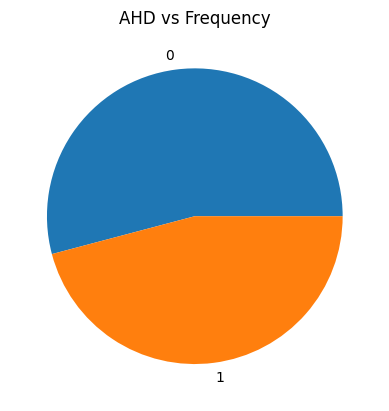

In [48]:
plt.pie(df['AHD'].value_counts(),labels=df['AHD'].value_counts().index)
plt.title("AHD vs Frequency")
plt.show()

In [63]:
# DATA PREPROCESSING
# Dataset: melb_data.csv
# Apply data preprocessing and exploratory data analysis on melb_data.csv. Evaluate the dataset using summary statistics, and plot one
# visualization.

df=pd.read_csv("melb_data.csv")
print(df.head(5))

   Unnamed: 0      Suburb           Address  Rooms Type      Price Method  \
0           1  Abbotsford      85 Turner St      2    h  1480000.0      S   
1           2  Abbotsford   25 Bloomburg St      2    h  1035000.0      S   
2           4  Abbotsford      5 Charles St      3    h  1465000.0     SP   
3           5  Abbotsford  40 Federation La      3    h   850000.0     PI   
4           6  Abbotsford       55a Park St      4    h  1600000.0     VB   

  SellerG       Date  Distance  ...  Bathroom  Car  Landsize  BuildingArea  \
0  Biggin  3/12/2016       2.5  ...       1.0  1.0     202.0           NaN   
1  Biggin  4/02/2016       2.5  ...       1.0  0.0     156.0          79.0   
2  Biggin  4/03/2017       2.5  ...       2.0  0.0     134.0         150.0   
3  Biggin  4/03/2017       2.5  ...       2.0  1.0      94.0           NaN   
4  Nelson  4/06/2016       2.5  ...       1.0  2.0     120.0         142.0   

   YearBuilt  CouncilArea  Lattitude Longtitude             Regionna

In [64]:
# remove 
df=df.drop('Unnamed: 0',axis=1)

In [65]:
print(df.head(5))

       Suburb           Address  Rooms Type      Price Method SellerG  \
0  Abbotsford      85 Turner St      2    h  1480000.0      S  Biggin   
1  Abbotsford   25 Bloomburg St      2    h  1035000.0      S  Biggin   
2  Abbotsford      5 Charles St      3    h  1465000.0     SP  Biggin   
3  Abbotsford  40 Federation La      3    h   850000.0     PI  Biggin   
4  Abbotsford       55a Park St      4    h  1600000.0     VB  Nelson   

        Date  Distance  Postcode  ...  Bathroom  Car  Landsize  BuildingArea  \
0  3/12/2016       2.5    3067.0  ...       1.0  1.0     202.0           NaN   
1  4/02/2016       2.5    3067.0  ...       1.0  0.0     156.0          79.0   
2  4/03/2017       2.5    3067.0  ...       2.0  0.0     134.0         150.0   
3  4/03/2017       2.5    3067.0  ...       2.0  1.0      94.0           NaN   
4  4/06/2016       2.5    3067.0  ...       1.0  2.0     120.0         142.0   

   YearBuilt  CouncilArea Lattitude  Longtitude             Regionname  \
0     

In [66]:
# find d types
df.dtypes

Suburb            object
Address           object
Rooms              int64
Type              object
Price            float64
Method            object
SellerG           object
Date              object
Distance         float64
Postcode         float64
Bedroom2         float64
Bathroom         float64
Car              float64
Landsize         float64
BuildingArea     float64
YearBuilt        float64
CouncilArea       object
Lattitude        float64
Longtitude       float64
Regionname        object
Propertycount    float64
dtype: object

In [67]:
df.isnull().sum()

Suburb               0
Address              0
Rooms                0
Type                 0
Price                0
Method               0
SellerG              0
Date                 0
Distance             1
Postcode             1
Bedroom2          3469
Bathroom          3471
Car               3576
Landsize          4793
BuildingArea     10634
YearBuilt         9438
CouncilArea       6163
Lattitude         3332
Longtitude        3332
Regionname           1
Propertycount        1
dtype: int64

In [68]:
df.duplicated().sum()

np.int64(0)

In [69]:
# remove duplicate value
df=df.drop_duplicates()

In [70]:
# handle null value

for col in df.columns:
    if df[col].dtypes=='object':
        df[col]=df[col].fillna(df[col].mode().iloc[0])
    else:
        df[col]=df[col].fillna(df[col].mean())

print(df.head(5))
    

       Suburb           Address  Rooms Type      Price Method SellerG  \
0  Abbotsford      85 Turner St      2    h  1480000.0      S  Biggin   
1  Abbotsford   25 Bloomburg St      2    h  1035000.0      S  Biggin   
2  Abbotsford      5 Charles St      3    h  1465000.0     SP  Biggin   
3  Abbotsford  40 Federation La      3    h   850000.0     PI  Biggin   
4  Abbotsford       55a Park St      4    h  1600000.0     VB  Nelson   

        Date  Distance  Postcode  ...  Bathroom  Car  Landsize  BuildingArea  \
0  3/12/2016       2.5    3067.0  ...       1.0  1.0     202.0    151.220219   
1  4/02/2016       2.5    3067.0  ...       1.0  0.0     156.0     79.000000   
2  4/03/2017       2.5    3067.0  ...       2.0  0.0     134.0    150.000000   
3  4/03/2017       2.5    3067.0  ...       2.0  1.0      94.0    151.220219   
4  4/06/2016       2.5    3067.0  ...       1.0  2.0     120.0    142.000000   

     YearBuilt  CouncilArea Lattitude  Longtitude             Regionname  \
0  1

In [62]:
# # label encoding
# from sklearn.preprocessing import LabelEncoder

# label=LabelEncoder()
# for col in df.columns:
#     if df[col].dtypes=='object':
#         df[col]=label.fit_transform(df[col])

# print(df.head(5))

   Suburb  Address  Rooms  Type      Price  Method  SellerG  Date  Distance  \
0       0    17365      2     0  1480000.0       1       29    45       2.5   
1       0     8233      2     0  1035000.0       1       29    47       2.5   
2       0    13470      3     0  1465000.0       3       29    48       2.5   
3       0    12439      3     0   850000.0       0       29    48       2.5   
4       0    14496      4     0  1600000.0       4      178    49       2.5   

   Postcode  ...  Bathroom  Car  Landsize  BuildingArea    YearBuilt  \
0    3067.0  ...       1.0  1.0     202.0    151.220219  1965.879996   
1    3067.0  ...       1.0  0.0     156.0     79.000000  1900.000000   
2    3067.0  ...       2.0  0.0     134.0    150.000000  1900.000000   
3    3067.0  ...       2.0  1.0      94.0    151.220219  1965.879996   
4    3067.0  ...       1.0  2.0     120.0    142.000000  2014.000000   

   CouncilArea  Lattitude  Longtitude  Regionname  Propertycount  
0           31   -37.7996

In [71]:
df['Suburb'].value_counts()

Suburb
Reservoir         541
Bentleigh East    368
Richmond          333
Preston           312
Brunswick         286
                 ... 
Wallan              1
Laverton            1
Plumpton            1
croydon             1
Monbulk             1
Name: count, Length: 330, dtype: int64

In [72]:
col=['Suburb','Type']
for c in col:
    df=pd.get_dummies(df,columns=[c],drop_first=True,dtype='int')
print(df.head(5))

            Address  Rooms      Price Method SellerG       Date  Distance  \
0      85 Turner St      2  1480000.0      S  Biggin  3/12/2016       2.5   
1   25 Bloomburg St      2  1035000.0      S  Biggin  4/02/2016       2.5   
2      5 Charles St      3  1465000.0     SP  Biggin  4/03/2017       2.5   
3  40 Federation La      3   850000.0     PI  Biggin  4/03/2017       2.5   
4       55a Park St      4  1600000.0     VB  Nelson  4/06/2016       2.5   

   Postcode  Bedroom2  Bathroom  ...  Suburb_Windsor  Suburb_Wollert  \
0    3067.0       2.0       1.0  ...               0               0   
1    3067.0       2.0       1.0  ...               0               0   
2    3067.0       3.0       2.0  ...               0               0   
3    3067.0       3.0       2.0  ...               0               0   
4    3067.0       3.0       1.0  ...               0               0   

   Suburb_Wonga Park  Suburb_Wyndham Vale Suburb_Yallambie  Suburb_Yarra Glen  \
0                  0   

In [73]:
df.describe()

,Rooms,Price,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,...,Suburb_Windsor,Suburb_Wollert,Suburb_Wonga Park,Suburb_Wyndham Vale,Suburb_Yallambie,Suburb_Yarra Glen,Suburb_Yarraville,Suburb_croydon,Type_t,Type_u
count,18396.000000,1.839600e+04,18396.000000,18396.000000,18396.000000,18396.000000,18396.000000,18396.000000,18396.000000,18396.000000,...,18396.000000,18396.00000,18396.000000,18396.000000,18396.000000,18396.000000,18396.000000,18396.000000,18396.000000,18396.000000
mean,2.935040,1.056697e+06,10.389986,3107.140147,2.913043,1.538492,1.615520,558.116371,151.220219,1965.879996,...,0.003588,0.00087,0.000054,0.000761,0.002011,0.000054,0.010057,0.000054,0.108991,0.233529
std,0.958202,6.419217e+05,6.008886,94.998413,0.868936,0.620880,0.857984,3428.730081,337.236125,25.827879,...,0.059792,0.02948,0.007373,0.027577,0.044804,0.007373,0.099779,0.007373,0.311636,0.423087
min,1.000000,8.500000e+04,0.000000,3000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1196.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,6.330000e+05,6.300000,3046.000000,2.000000,1.000000,1.000000,250.750000,140.000000,1965.879996,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.000000,8.800000e+05,9.700000,3085.000000,3.000000,1.538492,1.615520,558.116371,151.220219,1965.879996,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,3.000000,1.302000e+06,13.300000,3149.000000,3.000000,2.000000,2.000000,596.000000,151.220219,1970.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,12.000000,9.000000e+06,48.100000,3978.000000,20.000000,8.000000,10.000000,433014.000000,44515.000000,2018.000000,...,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [75]:
df.dtypes

Address               object
Rooms                  int64
Price                float64
Method                object
SellerG               object
                      ...   
Suburb_Yarra Glen      int64
Suburb_Yarraville      int64
Suburb_croydon         int64
Type_t                 int64
Type_u                 int64
Length: 350, dtype: object

In [78]:
X=df.drop(columns=['Address','Method','SellerG','Price'])
y=df[['Price']]

print(x.dtypes)
print(y.dtypes)

Age            int64
Sex            int64
ChestPain      int64
RestBP         int64
Chol           int64
Fbs            int64
RestECG        int64
MaxHR          int64
ExAng          int64
Oldpeak      float64
Slope          int64
Ca           float64
Thal           int64
dtype: object
Price    float64
dtype: object


In [79]:
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)
print(len(x_train))
print(len(x_test))
print(len(y_train))
print(len(y_test))


13797
4599
13797
4599


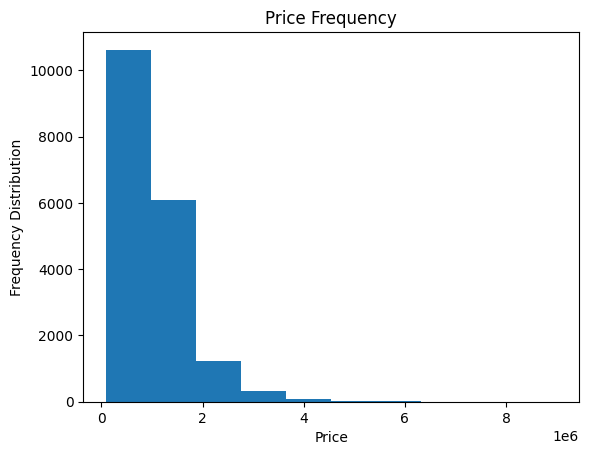

In [80]:
# visulazation
plt.hist(df['Price'],bins=10)
plt.xlabel("Price")
plt.ylabel("Frequency Distribution")
plt.title("Price Frequency")
plt.show()

In [3]:
# DATA PREPROCESSING
# Dataset: train.csv (Titanic dataset)
# Apply data preprocessing and exploratory data analysis on train.csv (Titanic dataset). Evaluate the dataset using summary statistics,
# and plot one visualization.


df=pd.read_csv("train.csv")
print(df.head(5))

   battery_power  blue  clock_speed  dual_sim  fc  four_g  int_memory  m_dep  \
0            842     0          2.2         0   1       0           7    0.6   
1           1021     1          0.5         1   0       1          53    0.7   
2            563     1          0.5         1   2       1          41    0.9   
3            615     1          2.5         0   0       0          10    0.8   
4           1821     1          1.2         0  13       1          44    0.6   

   mobile_wt  n_cores  ...  px_height  px_width   ram  sc_h  sc_w  talk_time  \
0        188        2  ...         20       756  2549     9     7         19   
1        136        3  ...        905      1988  2631    17     3          7   
2        145        5  ...       1263      1716  2603    11     2          9   
3        131        6  ...       1216      1786  2769    16     8         11   
4        141        2  ...       1208      1212  1411     8     2         15   

   three_g  touch_screen  wifi  price_

In [82]:
df.dtypes

battery_power      int64
blue               int64
clock_speed      float64
dual_sim           int64
fc                 int64
four_g             int64
int_memory         int64
m_dep            float64
mobile_wt          int64
n_cores            int64
pc                 int64
px_height          int64
px_width           int64
ram                int64
sc_h               int64
sc_w               int64
talk_time          int64
three_g            int64
touch_screen       int64
wifi               int64
price_range        int64
dtype: object

In [83]:
df.isnull().sum()

battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

In [84]:
df.duplicated().sum()

np.int64(0)

In [85]:
df.describe()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

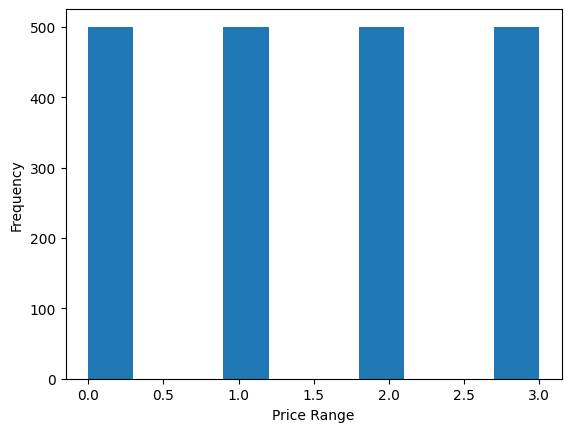

In [88]:
plt.hist(df['price_range'],bins=10)
plt.xlabel("Price Range")
plt.ylabel("Frequency")
plt.show()